# 01 — Data exploration

What the CirCor DigiScope data looks like, measured with the next steps in mind. This is where the project
starts: before choosing a model, every planned idea (which band, which window, how to handle the Unknown class)
is checked against the data.

1. **Population and file consistency** — what one prediction per patient has to combine.
2. **Labels below the patient** — which recordings of a Present patient actually carry the murmur.
3. **Segmentation and noise** — how much of each recording the annotators marked, and whether that tracks the label.
4. **Spectra** — which frequency band matters, and whether systole/diastole crops isolate the murmur.
5. **Spectrogram choice** — linear vs mel in this band.
6. **A quality score without segmentation** — the hidden set may not include `.tsv` files.
7. **Unknown by age** — where Unknown concentrates, and whether the noise band is really age.

Each section ends with what it means for the design. Code is in the `murmur` package; this notebook only calls it.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Audio, display

from murmur.core.constants import CLASSES
from murmur.data import audit, circor, labels
from murmur.preprocess import spectral, survey
from murmur.viz import recording

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"Present": "tab:red", "Unknown": "tab:orange", "Absent": "tab:blue"}
LISTEN = False   # True to play example recordings (audio is not saved in the committed notebook)

## 1. Population and file consistency

In [2]:
patients, recordings = circor.patients(), circor.recordings()
rec_labels = labels.recording_labels(patients, recordings)
summary = pd.DataFrame({
    "patients": patients["murmur"].value_counts(),
    "recordings": rec_labels["murmur"].value_counts(),
}).loc[list(CLASSES)]
summary["% patients"] = (100 * summary["patients"] / summary["patients"].sum()).round(1)
summary

,patients,recordings,% patients
murmur,,,
Present,179,616,19.0
Unknown,68,156,7.2
Absent,695,2391,73.8


In [3]:
per_patient = recordings.groupby("patient_id").size()
print("recordings per patient:", per_patient.value_counts().sort_index().to_dict())
print("recordings per location:", recordings["location"].value_counts().to_dict())
print("locations recorded more than once:", (recordings["repeat"] > 0).sum(), "recordings")
print("sample rates:", recordings["sample_rate"].value_counts().to_dict())
recordings["duration"].describe().round(1).to_frame("duration (s)").T

recordings per patient: {1: 62, 2: 156, 3: 123, 4: 588, 5: 10, 6: 3}
recordings per location: {'MV': 861, 'AV': 800, 'PV': 766, 'TV': 732, 'Phc': 4}
locations recorded more than once: 43 recordings
sample rates: {4000: 3163}


,count,mean,std,min,25%,50%,75%,max
duration (s),3163.0,22.9,7.3,5.2,19.1,21.5,29.4,64.5


In [4]:
checks = {
    "CSV / .txt / files disagree on locations": audit.location_mismatches(patients, recordings),
    "murmur location without a recording": audit.murmur_locations_not_recorded(patients, recordings),
    "recording without .tsv": audit.missing_segmentations(recordings),
    "invalid .tsv": audit.invalid_segmentations(recordings),
}
for name, rows in checks.items():
    print(f"{name}: {len(rows)}")
checks["invalid .tsv"]

CSV / .txt / files disagree on locations: 0
murmur location without a recording: 0
recording without .tsv: 0
invalid .tsv: 1


,recording_id,rows,unknown_states,span
0,50782_MV_1,1,[28],0


**For the design.** A patient has up to 6 recordings (usually 4, one per valve). The files are consistent with the
patient table. One `.tsv` is corrupt and is excluded wherever the segmentation is used. Durations vary a lot, so
inputs are cut into fixed-length windows rather than padded to the longest recording.

## 2. Labels below the patient

The label belongs to the patient, and `Murmur locations` says at which valves the murmur was heard. A recording of a
Present patient at another valve may contain no audible murmur. Labelling its windows "Present" would teach the
network that murmur-free audio is a murmur.

In [5]:
present = rec_labels[rec_labels["murmur"] == "Present"]
counts = present["at_murmur_location"].value_counts().rename({True: "at a murmur location", False: "elsewhere"})
print(f"Present patients' recordings: {len(present)}")
print((counts / len(present) * 100).round(1).astype(str).add(" %").to_string())

Present patients' recordings: 616
at_murmur_location
at a murmur location    81.0 %
elsewhere               19.0 %


In [6]:
p = patients[patients["murmur"] == "Present"]
pd.concat({c: p[c].value_counts(dropna=False) for c in
           ["systolic_timing", "systolic_pitch", "diastolic_timing"]}, axis=1).fillna(0).astype(int)

,systolic_timing,systolic_pitch,diastolic_timing
Holosystolic,101,0,0
Early-systolic,59,0,0
Mid-systolic,17,0,0
NaN,1,1,174
Late-systolic,1,0,0
Low,0,87,0
Medium,0,49,0
High,0,42,0
Early-diastolic,0,0,5


**For the design.**
- Window labels: about one in five recordings of Present patients is away from the murmur locations. For training,
  these are either excluded or given their own label. For patient-level evaluation the rule stays one label per
  patient.
- Almost every murmur is **systolic** (only 5 patients have a diastolic one). If cycle-aligned crops are used, systole
  is the crop that matters.
- The pitch descriptor (Low/Medium/High) lets section 4 check the frequency band against the experts' own description.

## 3. Segmentation and noise

The `.tsv` marks S1, systole, S2 and diastole. Time with no state ("unmarked") is time the annotators did not segment.
It is split here into the **edges** (before the first or after the last marked state) and the **interior** (gaps
between cycles).

In [7]:
seg = survey.segmentation_table(recordings).join(rec_labels[["murmur"]])
by_class = seg.groupby("murmur")[["unmarked", "unmarked_edges", "unmarked_interior"]].mean().loc[list(CLASSES)]
patient_level = seg.join(rec_labels["patient_id"]).groupby(["patient_id", "murmur"])["unmarked"].mean()
by_class["unmarked, patient mean"] = patient_level.groupby("murmur").mean()
by_class.round(3)

,unmarked,unmarked_edges,unmarked_interior,"unmarked, patient mean"
murmur,,,,
Present,0.393,0.390,0.003,0.427
Unknown,0.688,0.657,0.032,0.726
Absent,0.444,0.441,0.003,0.472


cycle length (s): {'25%': 0.5, '50%': 0.58, '75%': 0.66}


location,AV,MV,PV,Phc,TV
"unmarked, by location",0.521,0.512,0.37,0.366,0.367


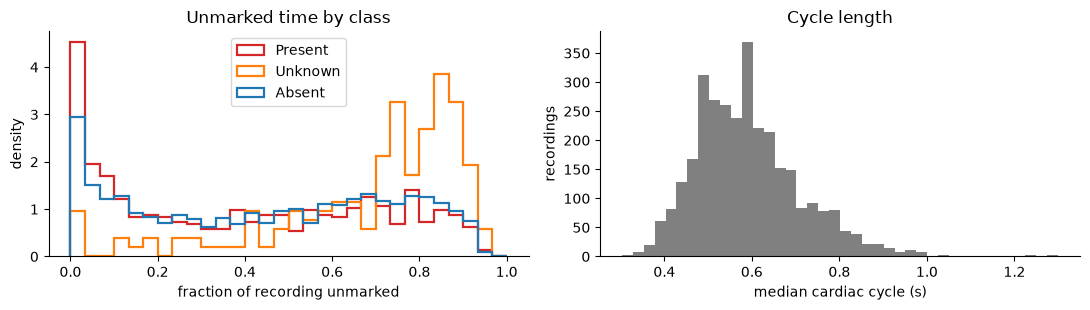

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for c in CLASSES:
    axes[0].hist(seg.loc[seg["murmur"] == c, "unmarked"].dropna(), bins=30, range=(0, 1),
                 density=True, histtype="step", lw=1.6, color=COLORS[c], label=c)
axes[0].set(xlabel="fraction of recording unmarked", ylabel="density", title="Unmarked time by class")
axes[0].legend()
axes[1].hist(seg["cycle_s"].dropna(), bins=40, color="grey")
axes[1].set(xlabel="median cardiac cycle (s)", ylabel="recordings", title="Cycle length")
plt.tight_layout()
print("cycle length (s):", seg["cycle_s"].describe()[["25%", "50%", "75%"]].round(2).to_dict())
seg.groupby(recordings["location"])["unmarked"].mean().round(3).to_frame("unmarked, by location").T

**For the design.**
- **The unmarked time is almost all at the edges.** The annotators marked one contiguous clean stretch per recording
  and left out the rest. It is not scattered gaps.
- **Unknown recordings have much less marked:** about two thirds of each one is unmarked, against under half for the
  other classes, and 10x more interior gaps. The segmentation encodes how usable the signal was, which is what Unknown
  means. Cropping to marked regions would throw this evidence away, so whatever is rejected has to be **counted**.
- A cycle lasts about 0.5–0.66 s (children's heart rates are high). A 2–4 s window holds 3–7 cycles.
- AV and MV recordings are less marked than PV and TV. Location is worth keeping as an input or in the aggregation.

## 4. Spectra

Average power spectra of the raw signal by class, of systoles vs diastoles, and of Present patients by the pitch the
experts described. Only recordings at a murmur location are used for Present.

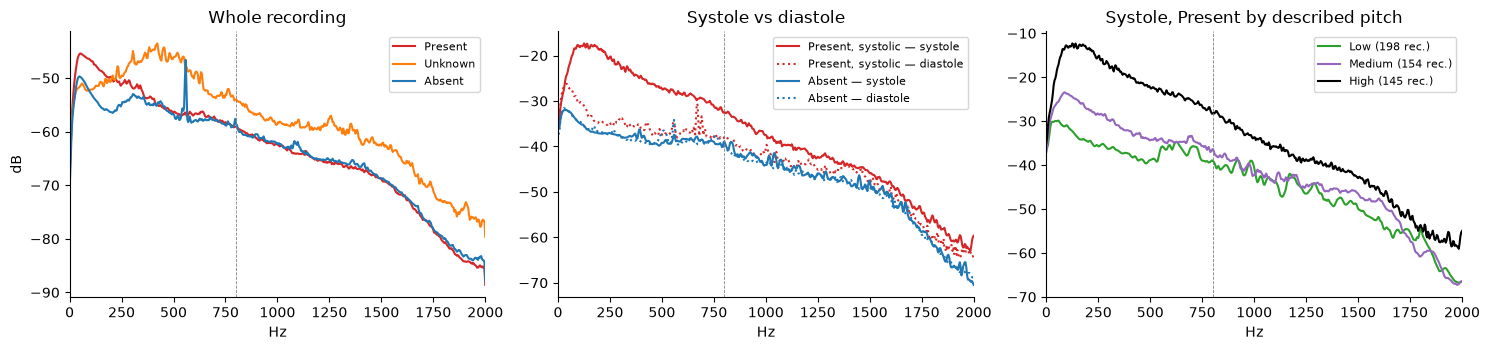

In [9]:
spec = survey.spectra(recordings)
f = spec["freqs"]
db = lambda rows: 10 * np.log10(np.nanmean(rows, axis=0) + 1e-12)
at_loc = (rec_labels["murmur"] != "Present") | rec_labels["at_murmur_location"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=False)
for c in CLASSES:
    mask = ((rec_labels["murmur"] == c) & at_loc).to_numpy()
    axes[0].plot(f, db(spec["whole"][mask]), color=COLORS[c], label=c)
axes[0].set(title="Whole recording", xlabel="Hz", ylabel="dB")
systolic = (rec_labels["murmur"] == "Present") & rec_labels["at_murmur_location"] & rec_labels["systolic_timing"].notna()
absent = rec_labels["murmur"] == "Absent"
for name, mask, color in (("Present, systolic", systolic, COLORS["Present"]), ("Absent", absent, COLORS["Absent"])):
    for part, ls in (("systole", "-"), ("diastole", ":")):
        axes[1].plot(f, db(spec[part][mask.to_numpy()]), color=color, ls=ls, label=f"{name} — {part}")
axes[1].set(title="Systole vs diastole", xlabel="Hz")
for pitch, color in zip(("Low", "Medium", "High"), ("tab:green", "tab:purple", "black")):
    mask = (systolic & (rec_labels["systolic_pitch"] == pitch)).to_numpy()
    axes[2].plot(f, db(spec["systole"][mask]), color=color, label=f"{pitch} ({mask.sum()} rec.)")
axes[2].set(title="Systole, Present by described pitch", xlabel="Hz")
for ax in axes:
    ax.set_xlim(0, 2000); ax.legend(fontsize=8); ax.axvline(800, color="grey", lw=0.6, ls="--")
plt.tight_layout()

In [10]:
bands = [(0, 25), (25, 200), (200, 400), (400, 800), (800, 2001)]
pd.DataFrame({c: spectral.band_shares(f, spec["whole"][((rec_labels["murmur"] == c) & at_loc).to_numpy()], bands)
              for c in CLASSES},
             index=[f"{lo}-{hi} Hz" for lo, hi in bands]).mul(100).round(1).rename_axis("median % of power")

,Present,Unknown,Absent
median % of power,,,
0-25 Hz,2.100000,1.0,2.100000
25-200 Hz,58.099998,25.0,47.799999
200-400 Hz,13.500000,19.5,13.900000
400-800 Hz,12.800000,28.1,17.500000
800-2001 Hz,4.400000,9.9,6.900000


**For the design.**
- **Systole crops isolate the murmur.** For Present patients (systolic murmur, at a murmur location), systole sits
  about 13 dB above diastole at 50–300 Hz. For Absent patients the two differ by about 2 dB. The comparison is within
  each recording, so it does not depend on recording loudness. Cycle-aligned input (or a window that the network can
  read as cycles) is worth testing.
- **The murmur is below about 400 Hz.** Above 800 Hz the classes run parallel, with Unknown highest. 25–800 Hz is a
  safe band-pass, and the upper limit could probably be lower; that gets checked on validation WA.
- **Unknown has a broad hump at 250–600 Hz**, where voices and handling noise sit. That band is evidence for Unknown,
  so it is kept rather than filtered away.
- **Described pitch shows as loudness, not as a shift in frequency:** all three pitch groups peak around 100–200 Hz.
  "High" murmurs are much louder on average. The pitch descriptor does not set the band.
- Absent has a narrow peak near 550 Hz: a tonal interference in some recordings, to identify later.

## 5. Linear vs mel in this band

The mel scale models how humans perceive pitch. Recordings are sampled at 4 kHz and the useful band is below about
800 Hz, where the mel scale is almost linear.

librosa default (Slaney): filter spacing 11.9 Hz at 25 Hz, 11.9 Hz at 800 Hz
HTK formula: filter spacing 8.2 Hz at 25 Hz, 16.5 Hz at 800 Hz


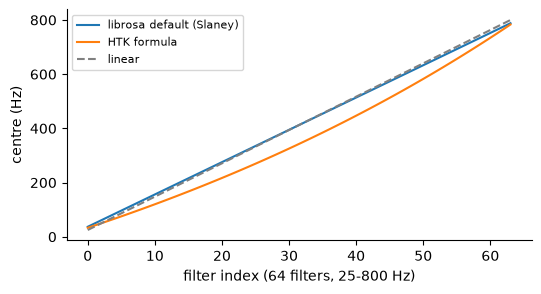

In [11]:
import librosa
linear = np.linspace(25, 800, 64)
fig, ax = plt.subplots(figsize=(6, 3))
for htk, label in ((False, "librosa default (Slaney)"), (True, "HTK formula")):
    centres = librosa.mel_frequencies(n_mels=66, fmin=25, fmax=800, htk=htk)[1:-1]
    ax.plot(centres, label=label)
    spacing = np.diff(centres)
    print(f"{label}: filter spacing {spacing[0]:.1f} Hz at 25 Hz, {spacing[-1]:.1f} Hz at 800 Hz")
ax.plot(linear, ls="--", color="grey", label="linear")
ax.set(xlabel="filter index (64 filters, 25-800 Hz)", ylabel="centre (Hz)"); ax.legend(fontsize=8)

**For the design.** librosa's default mel scale (Slaney) is **exactly linear below 1 kHz**, so in this band a
"mel spectrogram" is a linear spectrogram with triangular filters. The HTK formula is not linear here, but its filters
widen by only about 2x from 25 to 800 Hz. A transform toward human pitch perception changes little in this band. The
choices that matter more are the band, the STFT window (time vs frequency resolution) and log compression.
Linear-log vs HTK-mel vs MFCC is a cheap comparison on one model.

## 6. Examples, and a quality score without segmentation

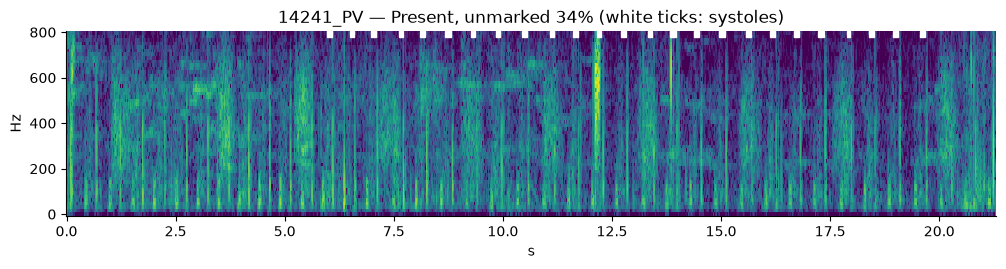

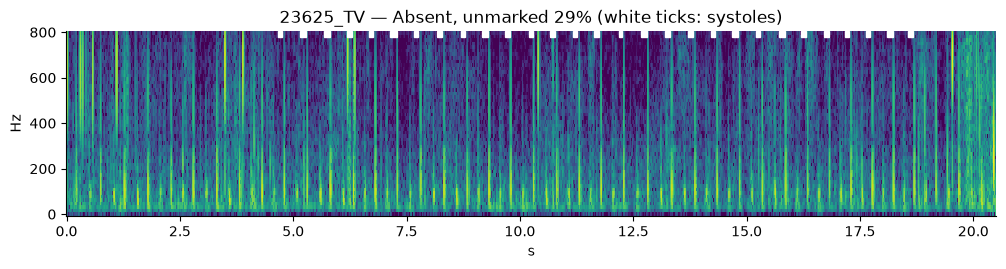

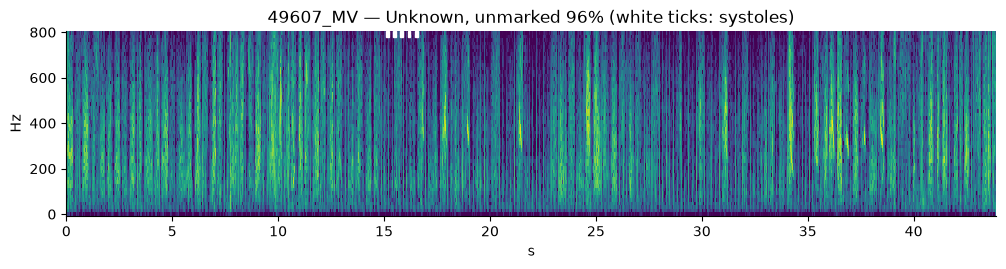

In [12]:
ok = seg["unmarked"].between(0.2, 0.5)
examples = [rec_labels[(rec_labels["murmur"] == "Present") & rec_labels["at_murmur_location"] & ok].index[0],
            rec_labels[(rec_labels["murmur"] == "Absent") & ok].index[0],
            seg[seg["murmur"] == "Unknown"]["unmarked"].idxmax()]
for rid in examples:
    recording.spectrogram(recordings.loc[rid], f"{rid} — {rec_labels.loc[rid, 'murmur']}, "
                          f"unmarked {seg.loc[rid, 'unmarked']:.0%} (white ticks: systoles)")
    if LISTEN:
        display(Audio(circor.audio(recordings.loc[rid]), rate=4000))

The hidden set may come without `.tsv` files, so a quality signal that needs the segmentation may not be available at
prediction time. Two scores computed from the audio alone, per 2 s window: the **share of power outside 25–400 Hz**
(speech and rubbing put energy above the heart band) and the **spectral flatness inside it** (noise is flat).

Spearman correlation with the window's unmarked fraction:
out_of_band    0.360
flatness       0.353


,out_of_band,flatness
murmur,,
Present,0.165,0.545
Unknown,0.354,0.691
Absent,0.193,0.509


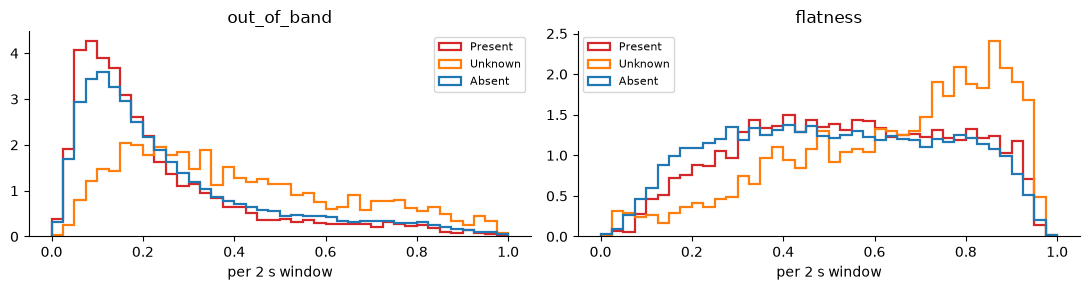

In [13]:
quality = survey.quality_table(recordings).join(rec_labels[["murmur"]], on="recording_id")
print("Spearman correlation with the window's unmarked fraction:")
print(quality[["out_of_band", "flatness"]].corrwith(quality["unmarked"], method="spearman").round(3).to_string())
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, col in zip(axes, ("out_of_band", "flatness")):
    for c in CLASSES:
        ax.hist(quality.loc[quality["murmur"] == c, col], bins=40, range=(0, 1), density=True,
                histtype="step", lw=1.6, color=COLORS[c], label=c)
    ax.set(title=col, xlabel="per 2 s window"); ax.legend(fontsize=8)
plt.tight_layout()
quality.groupby("murmur")[["out_of_band", "flatness"]].median().loc[list(CLASSES)].round(3)

**For the design.** Both scores rise where annotators left the signal unmarked, and both are highest for Unknown.
That is a starting point for a quality input that works without `.tsv` files, not a finished detector.

## 7. Unknown by age

Is Unknown spread evenly over the patients, or concentrated somewhere? And is the 250–600 Hz hump of section 4 a
property of Unknown recordings, or of who the patients are?

In [14]:
ages = ["Neonate", "Infant", "Child", "Adolescent"]
age = patients["age"].fillna("not given")
by_age = pd.crosstab(age, patients["murmur"])[list(CLASSES)].reindex(ages + ["not given"])
by_age["% Unknown"] = (100 * by_age["Unknown"] / by_age.sum(axis=1)).round(1)
by_age

murmur,Present,Unknown,Absent,% Unknown
age,,,,
Neonate,1,1,4,16.7
Infant,25,25,76,19.8
Child,132,37,495,5.6
Adolescent,16,3,53,4.2
not given,5,2,67,2.7


In [15]:
band = lambda lo, hi: spec["whole"][:, (f >= lo) & (f < hi)].sum(axis=1)
hump = pd.DataFrame({"share": band(250, 600) / band(25, 2000),
                     "age": age.loc[rec_labels["patient_id"]].to_numpy(), "murmur": rec_labels["murmur"].to_numpy()})
hump.pivot_table(index="age", columns="murmur", values="share", aggfunc="median").reindex(ages)[list(CLASSES)] \
    .round(3).rename_axis("median share of 25–2000 Hz power in 250–600 Hz")

murmur,Present,Unknown,Absent
median share of 25–2000 Hz power in 250–600 Hz,,,
Neonate,0.360,0.568,0.229
Infant,0.288,0.349,0.372
Child,0.184,0.293,0.187
Adolescent,0.151,0.234,0.172


**For the design.**
- **Unknown is concentrated in infants**: about one in five, against about one in twenty children and adolescents.
- **Infants carry about twice the 250–600 Hz share of children, whatever their label.** Within children, Unknown is
  still higher than Absent and Present; within infants it does not separate Unknown at all. So the hump is partly age (crying, a faster heart, a smaller chest) and only
  partly noise. Any band-energy quality score has to be compared **within age group**, or it mostly measures age.
- Whether age may be a model input is a question for the teacher. Notebook 02 measures noise in ways that do not
  depend on this band.

## What this changes

| Question | What the data says | Next step |
|---|---|---|
| Inputs | Recordings of 5–65 s, cycles of about 0.6 s | Fixed windows of 2–4 s with overlap, over the whole recording |
| Band | Murmur power is below about 400 Hz; Unknown is highest above 800 Hz | 25–800 Hz band-pass, checked on validation |
| Mel or linear | librosa mel is exactly linear below 1 kHz; HTK filters widen only about 2x | Compare linear-log / mel / MFCC on one model |
| Window labels | About 1 in 5 recordings of Present patients is away from the murmur locations | Exclude them, or give them their own label, in training |
| Cycle crops | Almost all murmurs are systolic; Present systole is about 13 dB above its diastole (Absent: about 2 dB) | Systole crops are worth an experiment if the hidden set has segmentation |
| Noise and Unknown | Unknown recordings are much less marked, have a 250–600 Hz hump, and score noisier on audio-only scores | Detect and count noise, never silently remove it; quality feeds the Unknown decision |
| Unknown and age | Unknown is 20 % of infants vs 6 % of children; the 250–600 Hz hump is largely age | Compare quality scores within age group; ask whether age may be an input |
| One prediction per patient | Up to 6 recordings; AV/MV noisier | Aggregate per location, then per patient, with the rule chosen on validation |